In [2]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Reproducibility setup
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)


In [5]:
# Load the raw dataset
df = pd.read_csv("../data/ai4i2020.csv")

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")
print("Column names and data types:")
print(df.dtypes)

display(df.head())

Dataset shape: 10,000 rows x 14 columns

Column names and data types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [7]:
df.describe(include='all')

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
unique,NaN,10000,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,M14860,L,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,5000.50000,NaN,NaN,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,NaN,NaN,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,NaN,NaN,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,NaN,NaN,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,NaN,NaN,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,NaN,NaN,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000


In [9]:
df.duplicated().sum()

np.int64(0)

In [13]:
df['Product ID'].duplicated().sum()

np.int64(0)

In [15]:
# 1. Checks for empty or whitespace-only strings in string columns
str_cols = df.select_dtypes(include=["object", "string"]).columns
print("=== WHITESPACE & PLACEHOLDER STRING CHECK ===")
placeholders = {"", "na", "n/a", "nan", "null", "none", "?", "-", "unknown", "missing"}

for col in str_cols:
    stripped = df[col].astype(str).str.strip()
    empty_count = (stripped == "").sum()
    placeholder_count = stripped.str.lower().isin(placeholders).sum()
    leading_trailing_ws = (df[col].astype(str) != stripped).sum()
    print(f"{col:<15} | Empty: {empty_count} | Placeholders: {placeholder_count} | Extra whitespace: {leading_trailing_ws}")

# 2. Exact category breakdown and Product ID prefix alignment
print("\n=== 'Type' CATEGORY VALUE COUNTS ===")
print(df["Type"].value_counts(dropna=False))
prefix_mismatch = (df["Product ID"].str[0] != df["Type"]).sum()
print(f"Product ID prefix vs 'Type' mismatches: {prefix_mismatch}")

# 3. Check numeric columns for infinite values or common sentinel numbers (-1, -99, -999, 9999)
num_cols = df.select_dtypes(include=[np.number]).columns
sentinels = [-9999, -999, -99, -1, 9999, 99999]
print("\n=== INFINITE & SENTINEL VALUE CHECK ===")
for col in num_cols:
    inf_count = np.isinf(df[col]).sum()
    sentinel_count = df[col].isin(sentinels).sum()
    if inf_count > 0 or sentinel_count > 0:
        print(f"Alert in {col}: inf={inf_count}, sentinels={sentinel_count}")
print("Numeric sentinel/infinity scan complete.")

# 4. Verify all binary target & failure-mode flags contain strictly {0, 1}
binary_cols = ["Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"]
invalid_binary = {col: set(df[col].unique()) - {0, 1} for col in binary_cols}
print("\n=== BINARY FLAG DOMAIN CHECK (Any non-{0,1} values) ===")
print(invalid_binary)

=== WHITESPACE & PLACEHOLDER STRING CHECK ===
Product ID      | Empty: 0 | Placeholders: 0 | Extra whitespace: 0
Type            | Empty: 0 | Placeholders: 0 | Extra whitespace: 0

=== 'Type' CATEGORY VALUE COUNTS ===
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64
Product ID prefix vs 'Type' mismatches: 0

=== INFINITE & SENTINEL VALUE CHECK ===
Alert in UDI: inf=0, sentinels=1
Numeric sentinel/infinity scan complete.

=== BINARY FLAG DOMAIN CHECK (Any non-{0,1} values) ===
{'Machine failure': set(), 'TWF': set(), 'HDF': set(), 'PWF': set(), 'OSF': set(), 'RNF': set()}


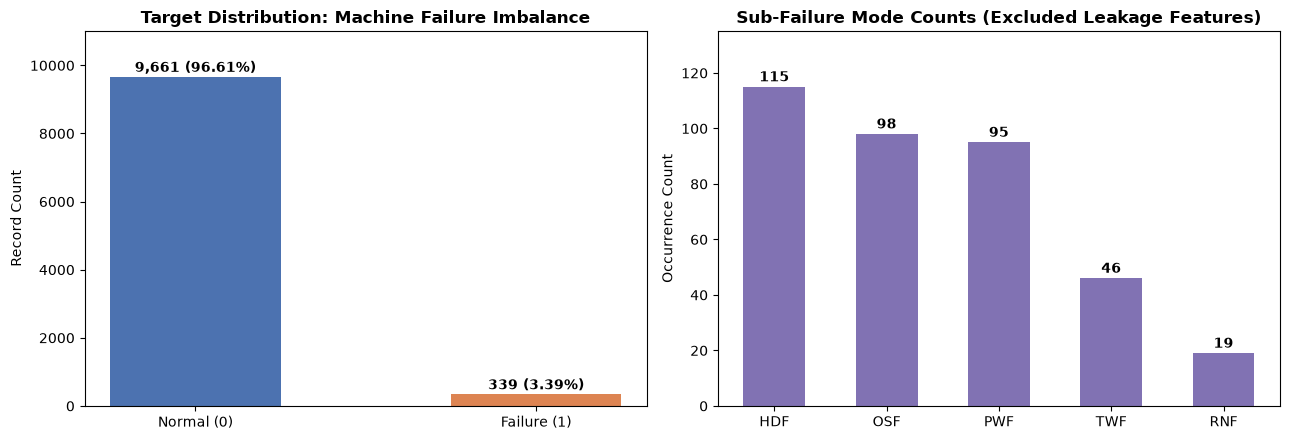

Any Mode Flag > 0     0    1
Machine failure             
0                  9643   18
1                     9  330


In [16]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Binary Target Distribution
counts = df["Machine failure"].value_counts()
pcts = df["Machine failure"].value_counts(normalize=True) * 100
bars = axes[0].bar(["Normal (0)", "Failure (1)"], counts.values, color=["#4C72B0", "#DD8452"], width=0.5)
axes[0].set_title("Target Distribution: Machine Failure Imbalance", fontweight="bold")
axes[0].set_ylabel("Record Count")
for bar, c, p in zip(bars, counts.values, pcts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, c + 150, f"{c:,} ({p:.2f}%)", ha="center", fontweight="bold")
axes[0].set_ylim(0, 11000)

# 2. Failure Mode Breakdown (Leakage Indicators)
mode_counts = df[failure_modes].sum().sort_values(ascending=False)
bars2 = axes[1].bar(mode_counts.index, mode_counts.values, color="#8172B3", width=0.55)
axes[1].set_title("Sub-Failure Mode Counts (Excluded Leakage Features)", fontweight="bold")
axes[1].set_ylabel("Occurrence Count")
for bar, c in zip(bars2, mode_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, c + 2, f"{c}", ha="center", fontweight="bold")
axes[1].set_ylim(0, 135)

plt.tight_layout()
plt.savefig("../reports/eda_target_and_modes.png", bbox_inches="tight")
plt.show()

# Verify exact relationship between failure modes and target
union_modes = (df[failure_modes].sum(axis=1) > 0).astype(int)
print(pd.crosstab(df["Machine failure"], union_modes, rownames=["Machine failure"], colnames=["Any Mode Flag > 0"]))

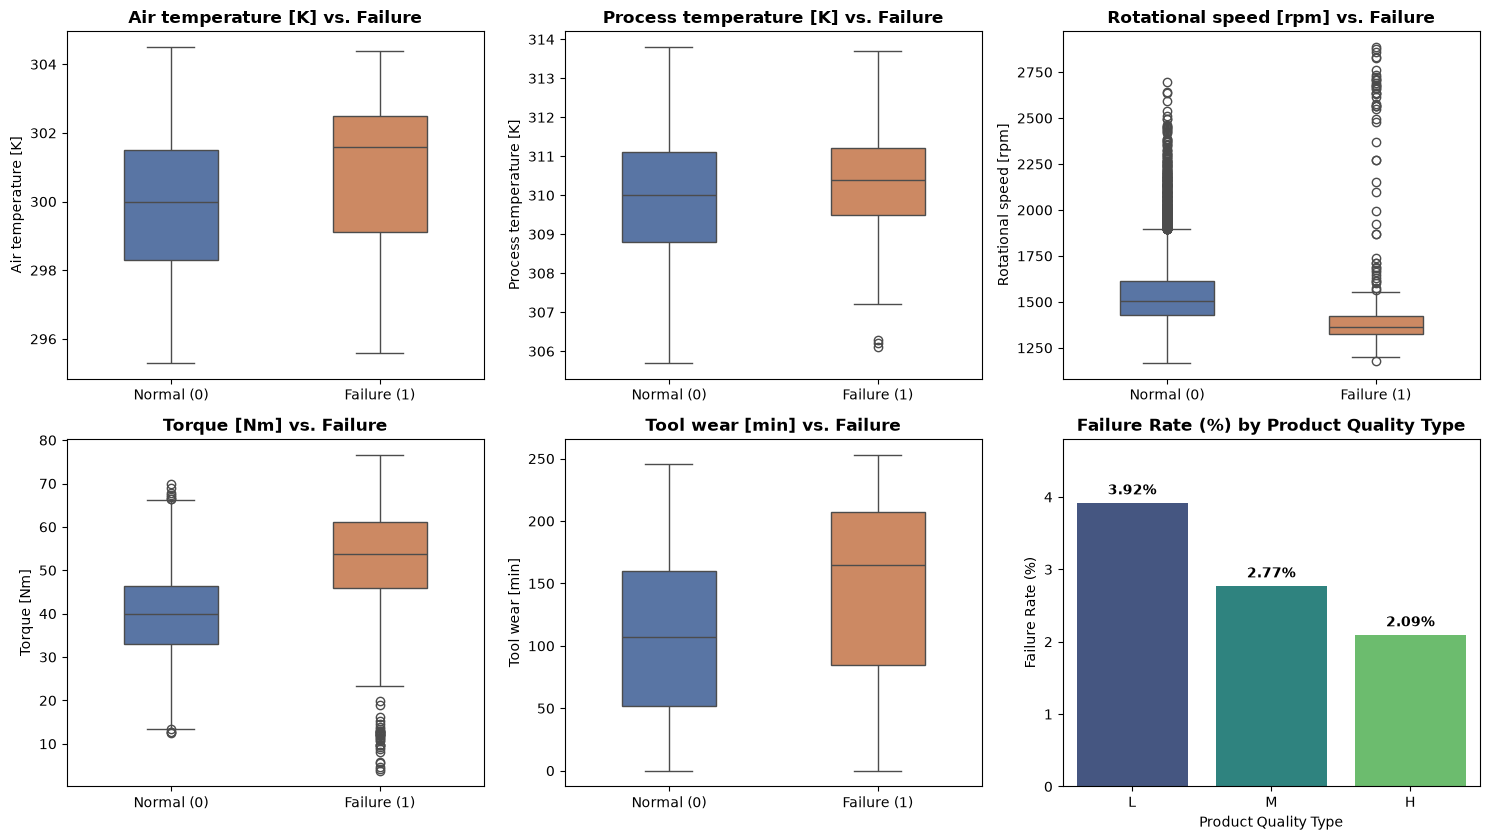

=== MANN-WHITNEY U TEST (NORMAL VS. FAILURE) ===
Air temperature [K]        | Normal Med:  300.00 | Fail Med:  301.60 | p = 8.66e-17
Process temperature [K]    | Normal Med:  310.00 | Fail Med:  310.40 | p = 6.49e-05
Rotational speed [rpm]     | Normal Med: 1507.00 | Fail Med: 1365.00 | p = 9.71e-63
Torque [Nm]                | Normal Med:   39.90 | Fail Med:   53.70 | p = 2.26e-64
Tool wear [min]            | Normal Med:  107.00 | Fail Med:  165.00 | p = 2.92e-24

=== CHI-SQUARE TEST ('Type' vs. Machine failure) ===
Chi2 = 13.7517, p = 1.0324e-03


In [17]:
sensor_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

# 1. Boxplots across Machine Failure + Failure Rate by Product Type
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.flatten()

for i, col in enumerate(sensor_cols):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=col,
        hue="Machine failure",
        palette=["#4C72B0", "#DD8452"],
        legend=False,
        width=0.45,
        ax=axes[i]
    )
    axes[i].set_title(f"{col} vs. Failure", fontweight="bold")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Normal (0)", "Failure (1)"])
    axes[i].set_xlabel("")

# Failure Rate by Product Quality Type
type_fail = df.groupby("Type")["Machine failure"].mean().reindex(["L", "M", "H"]) * 100
sns.barplot(x=type_fail.index, y=type_fail.values, hue=type_fail.index, palette="viridis", legend=False, ax=axes[5])
axes[5].set_title("Failure Rate (%) by Product Quality Type", fontweight="bold")
axes[5].set_ylabel("Failure Rate (%)")
axes[5].set_xlabel("Product Quality Type")
for idx, val in enumerate(type_fail.values):
    axes[5].text(idx, val + 0.12, f"{val:.2f}%", ha="center", fontweight="bold")
axes[5].set_ylim(0, 4.8)

plt.tight_layout()
plt.savefig("../reports/eda_sensor_distributions.png", bbox_inches="tight")
plt.show()

# 2. Quantitative Association Tests (Mann-Whitney U for continuous, Chi-Square for categorical)
print("=== MANN-WHITNEY U TEST (NORMAL VS. FAILURE) ===")
for col in sensor_cols:
    g0 = df[df["Machine failure"] == 0][col]
    g1 = df[df["Machine failure"] == 1][col]
    _, p_val = stats.mannwhitneyu(g0, g1, alternative="two-sided")
    print(f"{col:<26} | Normal Med: {g0.median():>7.2f} | Fail Med: {g1.median():>7.2f} | p = {p_val:.2e}")

contingency = pd.crosstab(df["Type"], df["Machine failure"])
chi2, p_chi2, _, _ = stats.chi2_contingency(contingency)
print(f"\n=== CHI-SQUARE TEST ('Type' vs. Machine failure) ===\nChi2 = {chi2:.4f}, p = {p_chi2:.4e}")

In [20]:
print("=== IQR OUTLIER & FAILURE CONCENTRATION AUDIT ===")
for col in sensor_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    
    is_outlier = (df[col] < lower) | (df[col] > upper)
    n_out = is_outlier.sum()
    
    if n_out > 0:
        fail_rate_out = df.loc[is_outlier, "Machine failure"].mean() * 100
        fail_count_out = df.loc[is_outlier, "Machine failure"].sum()
        print(
            f"{col:<25} | Outliers: {n_out:>3} ({n_out/len(df)*100:.2f}%) | "
            f"Failures in outliers: {fail_count_out:>2}/{n_out} ({fail_rate_out:.2f}%)"
        )
    else:
        print(f"{col:<25} | Outliers:   0")

=== IQR OUTLIER & FAILURE CONCENTRATION AUDIT ===
Air temperature [K]       | Outliers:   0
Process temperature [K]   | Outliers:   0
Rotational speed [rpm]    | Outliers: 418 (4.18%) | Failures in outliers: 35/418 (8.37%)
Torque [Nm]               | Outliers:  69 (0.69%) | Failures in outliers: 62/69 (89.86%)
Tool wear [min]           | Outliers:   0


In [21]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF", "Machine failure"]

def analyze_outlier_tails(df, col):
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    
    low_mask = df[col] < lower
    high_mask = df[col] > upper
    
    print(f"=== {col} (Bounds: [{lower:.2f}, {upper:.2f}]) ===")
    print(f"Lower-tail outliers (< {lower:.2f}): {low_mask.sum()} records")
    if low_mask.sum() > 0:
        print(df.loc[low_mask, failure_modes].sum().to_dict())
        
    print(f"Upper-tail outliers (> {upper:.2f}): {high_mask.sum()} records")
    if high_mask.sum() > 0:
        print(df.loc[high_mask, failure_modes].sum().to_dict())
    print()

analyze_outlier_tails(df, "Torque [Nm]")
analyze_outlier_tails(df, "Rotational speed [rpm]")

=== Torque [Nm] (Bounds: [12.80, 67.20]) ===
Lower-tail outliers (< 12.80): 28 records
{'TWF': 0, 'HDF': 0, 'PWF': 25, 'OSF': 0, 'RNF': 0, 'Machine failure': 25}
Upper-tail outliers (> 67.20): 41 records
{'TWF': 0, 'HDF': 3, 'PWF': 34, 'OSF': 9, 'RNF': 0, 'Machine failure': 37}

=== Rotational speed [rpm] (Bounds: [1139.50, 1895.50]) ===
Lower-tail outliers (< 1139.50): 0 records
Upper-tail outliers (> 1895.50): 418 records
{'TWF': 4, 'HDF': 0, 'PWF': 31, 'OSF': 0, 'RNF': 0, 'Machine failure': 35}



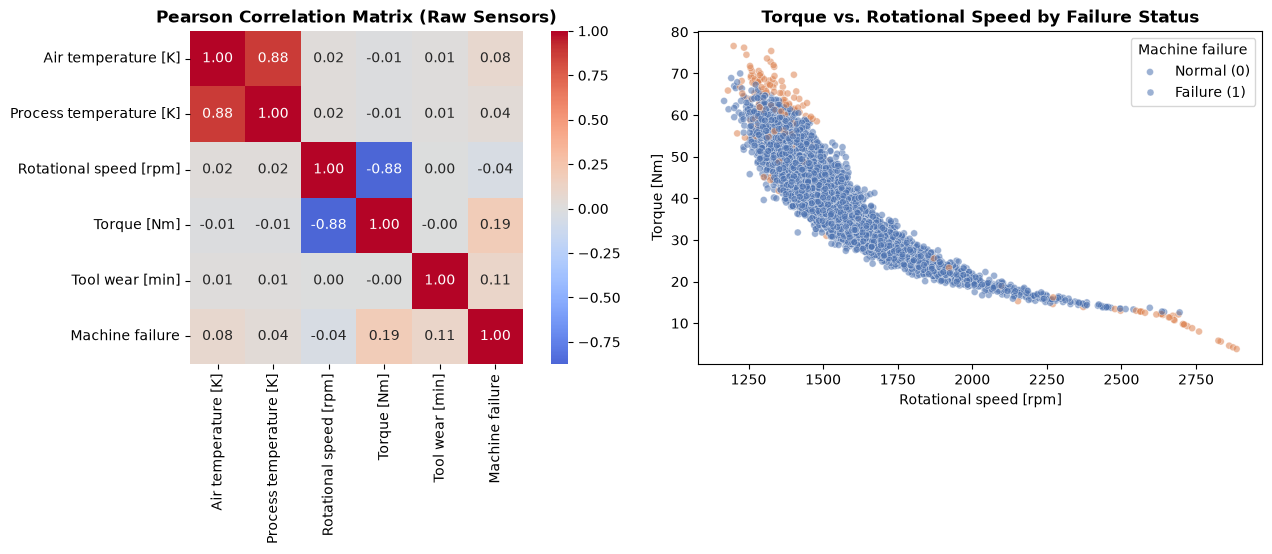

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Correlation Heatmap (Raw Sensors + Target)
corr = df[sensor_cols + ["Machine failure"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=axes[0])
axes[0].set_title("Pearson Correlation Matrix (Raw Sensors)", fontweight="bold")

# 2. Torque vs. Rotational Speed (reveals mechanical power & overstrain boundaries)
sns.scatterplot(
    data=df,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Machine failure",
    palette={0: "#4C72B0", 1: "#DD8452"},
    alpha=0.55,
    s=25,
    ax=axes[1]
)
axes[1].set_title("Torque vs. Rotational Speed by Failure Status", fontweight="bold")
axes[1].legend(title="Machine failure", labels=["Normal (0)", "Failure (1)"])

plt.tight_layout()
plt.savefig("../reports/eda_sensor_relationships.png", bbox_inches="tight")
plt.show()

## Phase 1 Summary: Data Quality & Exploratory Findings

### 1. Data Integrity & Structure
* **Dimensions & Completeness:** 10,000 records across 14 features with **0 missing values**, **0 duplicate rows**, and **0 duplicate Product IDs**.
* **Domain Validation:** All string columns (`Product ID`, `Type`) are clean with no whitespace or placeholder issues, and `Product ID` prefixes align 100% with the `Type` categories (`L`: 6,000, `M`: 2,997, `H`: 1,003). All binary flags strictly contain `{0, 1}`.

### 2. Target Distribution & Leakage Prevention
* **Class Imbalance:** The dataset exhibits severe class imbalance, with only **3.39% (339 cases)** resulting in `Machine failure` versus **96.61% (9,661 cases)** normal operation.
* **Leakage Features:** The five specific failure-mode flags (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) directly indicate failure states (330 of 339 failures trigger at least one mode flag; 18 normal records have a random/mode flag without triggering overall failure). These must be **excluded** from the modeling feature set in Phase 2 to prevent target leakage.

### 3. Feature Distributions & Statistical Significance
* **Physical Sensor Shifts:** Mann-Whitney $U$ tests confirm statistically significant differences ($p < 0.001$) between normal and failed states across all continuous physical sensors:
  * **Torque [Nm]:** Strongest shift—median rises from **39.90 Nm** (Normal) to **53.70 Nm** (Failure) ($p = 2.26 \times 10^{-64}$).
  * **Rotational speed [rpm]:** Right-skewed distribution with failures clustering at lower speeds—median drops from **1507 rpm** to **1365 rpm** ($p = 9.71 \times 10^{-63}$), alongside high-speed outliers.
  * **Temperatures [K]:** Both `Air temperature` (median **300.0 K $\rightarrow$ 301.6 K**, $p = 8.66 \times 10^{-17}$) and `Process temperature` (median **310.0 K $\rightarrow$ 310.4 K**, $p = 6.49 \times 10^{-5}$) show significant upward shifts during failures.
* **Tool Wear [min]:** Displays a distinct bimodal/elevated failure pattern at high wear levels (above ~200 min).
* **Product Type Impact:** Lower-quality variants (`L`) experience a noticeably higher failure rate compared to medium (`M`) and high (`H`) quality variants.

In [23]:
# 1. Define target and  excludes identifiers + failure-mode leakage columns
TARGET = "Machine failure"
EXCLUDE_COLS = ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF", TARGET]

X = df.drop(columns=EXCLUDE_COLS).copy()
y = df[TARGET].copy()

# 2. engineered features
X["Temp_diff [K]"] = X["Process temperature [K]"] - X["Air temperature [K]"]
X["Power [W]"] = X["Torque [Nm]"] * (X["Rotational speed [rpm]"] * 2 * np.pi / 60)
X["Wear_torque_load [Nm*min]"] = X["Tool wear [min]"] * X["Torque [Nm]"]

X["Power_deviation [W]"] = np.abs(X["Power [W]"] - 6250.0)
X["Torque_speed_ratio [Nm/rpm]"] = X["Torque [Nm]"] / X["Rotational speed [rpm]"]
X["Thermal_speed_risk [K/rpm]"] = X["Temp_diff [K]"] / X["Rotational speed [rpm]"]
X["Type_wear_limit_ratio"] = X["Tool wear [min]"] / X["Type"].map({"L": 180.0, "M": 200.0, "H": 220.0})

print(f"Final feature set ({X.shape[1]} predictors):", list(X.columns))

print("Final feature set (9 predictors):", list(X.columns))

# 3. Stratified 70% Train / 15% Validation / 15% Test split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_SEED
)

# 4. Fit preprocessing strictly on X_train to prevent data leakage
cat_features = ["Type"]
num_features = [col for col in X.columns if col not in cat_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(drop=None, sparse_output=False, handle_unknown="ignore"), cat_features),
    ]
)

X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

feature_names_proc = num_features + list(preprocessor.named_transformers_["cat"].get_feature_names_out(cat_features))

print(f"\nSplit shapes & positive failure rates:")
print(f"Train : {X_train_proc.shape} | Failures: {y_train.sum():>3} ({y_train.mean()*100:.2f}%)")
print(f"Val   : {X_val_proc.shape} | Failures: {y_val.sum():>3} ({y_val.mean()*100:.2f}%)")
print(f"Test  : {X_test_proc.shape} | Failures: {y_test.sum():>3} ({y_test.mean()*100:.2f}%)")

Final feature set (13 predictors): ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temp_diff [K]', 'Power [W]', 'Wear_torque_load [Nm*min]', 'Power_deviation [W]', 'Torque_speed_ratio [Nm/rpm]', 'Thermal_speed_risk [K/rpm]', 'Type_wear_limit_ratio']
Final feature set (9 predictors): ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temp_diff [K]', 'Power [W]', 'Wear_torque_load [Nm*min]', 'Power_deviation [W]', 'Torque_speed_ratio [Nm/rpm]', 'Thermal_speed_risk [K/rpm]', 'Type_wear_limit_ratio']

Split shapes & positive failure rates:
Train : (7000, 15) | Failures: 237 (3.39%)
Val   : (1500, 15) | Failures:  51 (3.40%)
Test  : (1500, 15) | Failures:  51 (3.40%)
